In [23]:
import torch
import torch.fft as fft
import torch.nn.functional as F


def generate_psf(N, wavelength, NA, refr_index, z_defocus_list, device='cuda'):
    """
    Generate PSFs for a list of defocus values.
    Args:
        N:             image size (NxN)
        wavelength:    wavelength in meters
        NA:            numerical aperture
        refr_index:    refractive index
        z_defocus_list: list or tensor of z values (meters)
    Returns: PSFs: (B, 1, N, N)
    """
    # batch size = number of z values
    z_defocus_list = torch.tensor(z_defocus_list, device=device).float()
    B = len(z_defocus_list)

    # Pupil coordinates (rho)
    x = torch.linspace(-1, 1, N, device=device)
    xx, yy = torch.meshgrid(x, x, indexing='ij')
    rho = torch.sqrt(xx**2 + yy**2)

    # Circular aperture
    aperture = (rho <= 1).float()  # 1 inside aperture

    # Wave number
    k = 2 * torch.pi / wavelength

    # Defocus phase term
    # sqrt(1 - (NA/n)^2 * rho^2) is approximated by 1 - rho^2 * NA^2/(2n^2)
    # More accurate version:
    phase = torch.sqrt(1 - (NA/refr_index)**2 * rho**2)

    # Expand for batch
    phase = phase.unsqueeze(0)  # (1, N, N)
    aperture = aperture.unsqueeze(0)        # (1, N, N)

    z = z_defocus_list.view(B, 1, 1)        # (B, 1, 1)

    pupil = aperture * torch.exp(1j * k * z * phase)    # (B, N, N)

    # Fourier transform to get PSF
    psf = fft.fftshift(fft.fft2(pupil), dim=(-2, -1))
    psf = torch.abs(psf) ** 2

    # Normalize
    psf = psf / psf.view(B, -1).sum(dim=1).view(B, 1, 1)

    return psf.unsqueeze(1)  # (B, 1, N, N)

def crop_psf(psf, k):
    """
    psf: (B, 1, N, N)
    returns cropped psf: (B, 1, k, k)
    """
    B, _, N, _ = psf.shape
    center = N // 2
    half = k // 2
    return psf[:, :, center-half:center+half+1,
                      center-half:center+half+1]


In [24]:
psf51_cpu.shape

(3, 1, 256, 256)

In [17]:
(psf51_cpu[0,0]).max()

np.float32(0.7788086)

/tmp/ipykernel_2542536/3462475165.py:18: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(psf51_cpu[0,0][127:129, 127:129], cmap='gray')
/tmp/ipykernel_2542536/3462475165.py:18: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(psf51_cpu[0,0][127:129, 127:129], cmap='gray')


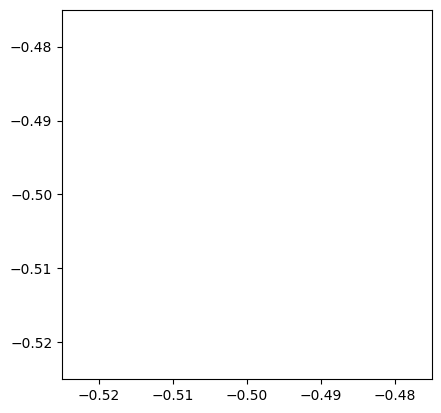

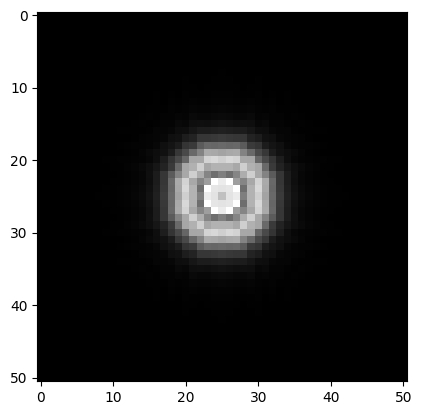

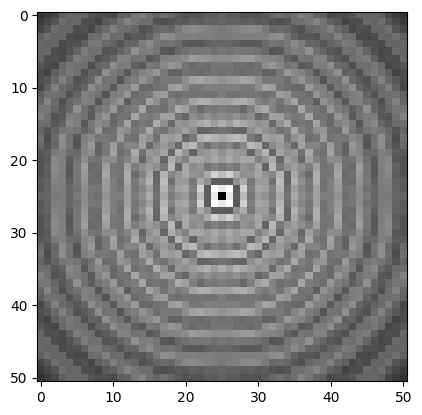

In [30]:
# Generate full PSF first
psf_full = generate_psf(
    N=256,
    wavelength=550e-9,
    NA=0.65,
    refr_index=1.0,
    z_defocus_list=[0, 5e-6, 3e-5],
    device='cuda'
)

# Crop to 51x51
psf51 = crop_psf(psf_full, k=51)
psf51 = psf51 / psf51.sum(dim=(2,3), keepdim=True)

psf51_cpu = psf51.cpu().numpy()
import numpy as np
import matplotlib.pyplot as plt
plt.imshow(psf51_cpu[0,0][127:129, 127:129], cmap='gray')
plt.show()
plt.imshow(psf51_cpu[1,0], cmap='gray')
plt.show()
plt.imshow(psf51_cpu[2,0], cmap='gray')
plt.show()